<a href="https://colab.research.google.com/github/hilalkaynarcali/goruntu-isleme/blob/main/quantization.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [7]:
from google.colab import files
yuklenen = files.upload()
dosya_adi = list(yuklenen.keys())[0]
print("Yüklenen dosya:", dosya_adi)

Saving image1.jpeg to image1.jpeg
Yüklenen dosya: image1.jpeg


orijinal min-max: 92 249
6 bit min-max: 23 62
orijinal seviye sayisi: 158
6 bit seviye sayisi: 40


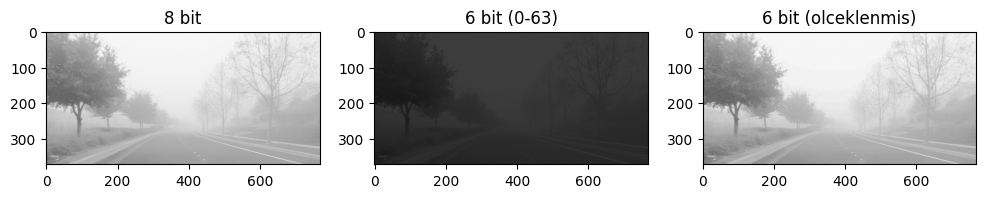

/tmp/ipykernel_1861/3127281766.py:32: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(img.ravel(), 256, [0, 255])
/tmp/ipykernel_1861/3127281766.py:35: MatplotlibDeprecationWarning: Passing the range parameter of hist() positionally is deprecated since Matplotlib 3.9; the parameter will become keyword-only in 3.11.
  plt.hist(yeni.ravel(), 256, [0, 255])


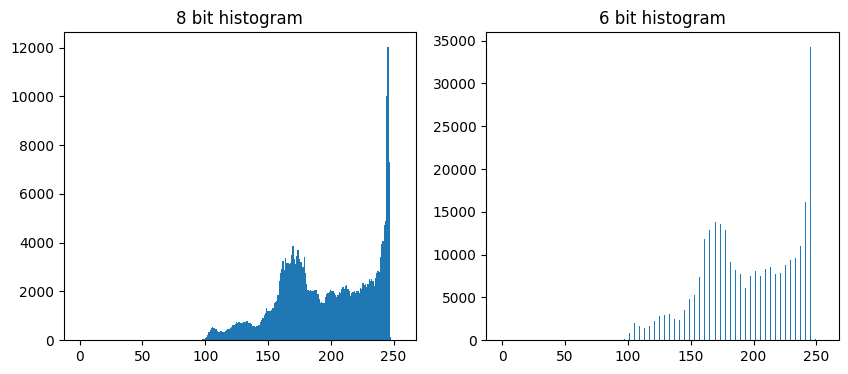

True

In [8]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

img = cv2.imread("image1.jpeg", 0)   # 0 = gri seviye

# 8 bit -> 6 bit
q6 = img // 4
yeni = (q6 * (255 / 63)).astype(np.uint8)

print("orijinal min-max:", img.min(), img.max())
print("6 bit min-max:", q6.min(), q6.max())
print("orijinal seviye sayisi:", len(np.unique(img)))
print("6 bit seviye sayisi:", len(np.unique(q6)))

# goruntuler
plt.figure(figsize=(12, 4))
plt.subplot(1, 3, 1)
plt.imshow(img, cmap="gray", vmin=0, vmax=255)
plt.title("8 bit")
plt.subplot(1, 3, 2)
plt.imshow(q6, cmap="gray", vmin=0, vmax=255)
plt.title("6 bit (0-63)")
plt.subplot(1, 3, 3)
plt.imshow(yeni, cmap="gray", vmin=0, vmax=255)
plt.title("6 bit (olceklenmis)")
plt.show()

# histogram
plt.figure(figsize=(10, 4))
plt.subplot(1, 2, 1)
plt.hist(img.ravel(), 256, [0, 255])
plt.title("8 bit histogram")
plt.subplot(1, 2, 2)
plt.hist(yeni.ravel(), 256, [0, 255])
plt.title("6 bit histogram")
plt.show()

cv2.imwrite("sonuc_6bit.png", yeni)